# Импорт библиотек

In [2]:
%pip install scikit-learn xgboost openpyxl pandas numpy matplotlib


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [16]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, RandomizedSearchCV, learning_curve, KFold, RepeatedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, VotingRegressor
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.feature_selection import RFECV, RFE
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline

import xgboost as xgb

file_path = r"magnetocaloric_perovskites_full_descriptors.xlsx"
out_dir = r"DCD_paper"

# Оформление графиков

In [4]:
# Константы для оформления графиков
CM_TO_INCH = 1 / 2.54
COLUMN_WIDTH = 8.5 * CM_TO_INCH

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",

    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8.5,

    "axes.linewidth": 0.9,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,

    "figure.dpi": 300,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

COLORS = {
    "blue": "#1f4e79",
    "red": "#b22222",
    "green": "#2e7d32",
    "gray": "#666666",
    "black": "#000000",
}


def save_figure(fig, name):
    fig.savefig(os.path.join(out_dir, f"{name}.png"), dpi=600)


def save_figure_to(fig, name, folder):
    fig.savefig(os.path.join(folder, f"{name}.png"), dpi=600)


def format_axes(ax, grid=True):
    ax.tick_params(direction="in", top=True, right=True)

    if grid:
        ax.grid(True, linestyle="--", linewidth=0.45, alpha=0.35)

    for spine in ax.spines.values():
        spine.set_linewidth(0.9)

# Функции построения графиков

In [5]:
def plot_delta_s_histogram(delta_s):
    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.hist(
        delta_s,
        bins=22,
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        alpha=0.88
    )

    ax.axvline(delta_s.mean(), color=COLORS["red"], linestyle="--",
               linewidth=1.1, label="Mean")
    ax.axvline(delta_s.median(), color=COLORS["black"], linestyle="-",
               linewidth=1.1, label="Median")

    ax.set_xlabel(r"$\Delta S_M$ (J kg$^{-1}$ K$^{-1}$)")
    ax.set_ylabel("Frequency")
    ax.set_title(r"Distribution of $\Delta S_M$")

    ax.legend(frameon=True, edgecolor="black", framealpha=1.0)
    format_axes(ax)

    fig.tight_layout(pad=0.4)
    save_figure(fig, "Fig1_delta_S_histogram")
    plt.show()


def plot_transformation_histogram(y_original):
    y_log = np.log1p(y_original)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.hist(
        y_original,
        bins=22,
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        alpha=0.88
    )

    ax.set_xlabel(r"$\Delta S_M$ (J kg$^{-1}$ K$^{-1}$)")
    ax.set_ylabel("Frequency")
    ax.set_title(r"Original $\Delta S_M$ distribution")

    format_axes(ax)
    fig.tight_layout(pad=0.4)
    save_figure(fig, "Fig2_original_distribution")
    plt.show()

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.hist(
        y_log,
        bins=22,
        color=COLORS["green"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        alpha=0.88
    )

    ax.set_xlabel(r"$\log(1+\Delta S_M)$")
    ax.set_ylabel("Frequency")
    ax.set_title(r"Log-transformed distribution")

    format_axes(ax)
    fig.tight_layout(pad=0.4)
    save_figure(fig, "Fig3_log_distribution")
    plt.show()


def plot_rfecv_curve(rfecv, optimal_k):
    if rfecv is None:
        print("RFECV plot skipped: RFECV was not performed.")
        return

    mean_scores = rfecv.cv_results_["mean_test_score"]
    n_features = np.arange(1, len(mean_scores) + 1)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.plot(
        n_features,
        mean_scores,
        marker="o",
        markersize=3.2,
        linewidth=1.2,
        color=COLORS["blue"],
        label=r"Mean CV $R^2$"
    )

    ax.axvline(
        optimal_k,
        color=COLORS["red"],
        linestyle="--",
        linewidth=1.1,
        label=f"Optimal: {optimal_k}"
    )

    ax.set_xlabel("Number of selected features")
    ax.set_ylabel(r"Cross-validation $R^2$")
    ax.set_title("RFECV feature selection")

    ax.legend(frameon=True, edgecolor="black", framealpha=1.0)
    format_axes(ax)

    fig.tight_layout(pad=0.4)
    save_figure(fig, "Fig4_rfecv_curve")
    plt.show()


def plot_feature_importance(imp_df, top_n=12):
    imp = imp_df.sort_values("rf_importance", ascending=True).tail(top_n)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 1.35))

    bars = ax.barh(
        imp["feature"],
        imp["rf_importance"],
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        height=0.68
    )

    xmax = imp["rf_importance"].max()
    ax.set_xlim(0, xmax * 1.28)

    for bar, value in zip(bars, imp["rf_importance"]):
        ax.text(
            value + xmax * 0.025,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center",
            ha="left",
            fontsize=7.5
        )

    ax.set_xlabel("Feature importance")
    ax.set_ylabel("Descriptor")
    ax.set_title("Random Forest feature importance")

    format_axes(ax)
    fig.tight_layout(pad=0.35)
    save_figure(fig, "Fig5_feature_importance_rf")
    plt.show()


def plot_model_comparison(results_df):
    res = results_df.sort_values("R2_transformed", ascending=True)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.85))

    bars = ax.barh(
        res["Model"],
        res["R2_transformed"],
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        height=0.68
    )

    xmax = max(res["R2_transformed"].max(), 0.1)
    ax.set_xlim(0, xmax * 1.25)

    for bar, value in zip(bars, res["R2_transformed"]):
        ax.text(
            value + xmax * 0.025,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center",
            ha="left",
            fontsize=7.5
        )

    ax.set_xlabel(r"Test $R^2$")
    ax.set_ylabel("Model")
    ax.set_title("Model performance")

    format_axes(ax)
    fig.tight_layout(pad=0.35)
    save_figure(fig, "Fig6_model_comparison")
    plt.show()


def plot_parity(y_true, y_pred, name="rf"):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)

    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    margin = 0.07 * (max_val - min_val)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH))

    ax.scatter(
        y_true,
        y_pred,
        s=22,
        color=COLORS["green"],
        edgecolor=COLORS["black"],
        linewidth=0.35,
        alpha=0.78
    )

    ax.plot(
        [min_val - margin, max_val + margin],
        [min_val - margin, max_val + margin],
        linestyle="--",
        linewidth=1.1,
        color=COLORS["red"],
        label="Ideal"
    )

    ax.text(
        0.06,
        0.94,
        rf"$R^2$ = {r2:.3f}" + "\n" +
        rf"MAE = {mae:.2f}",
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=8.5,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor="black",
            linewidth=0.6,
            alpha=0.92
        )
    )

    ax.set_xlabel(r"Experimental $\Delta S_M$" + "\n" + r"(J kg$^{-1}$ K$^{-1}$)")
    ax.set_ylabel(r"Predicted $\Delta S_M$" + "\n" + r"(J kg$^{-1}$ K$^{-1}$)")
    ax.set_title(r"Experimental vs predicted $\Delta S_M$")

    ax.set_xlim(min_val - margin, max_val + margin)
    ax.set_ylim(min_val - margin, max_val + margin)
    ax.set_aspect("equal", adjustable="box")

    ax.legend(frameon=True, edgecolor="black", framealpha=1.0, loc="lower right")
    format_axes(ax)

    fig.tight_layout(pad=0.35)
    save_figure(fig, f"Fig7_parity_plot_{name}")
    plt.show()


def plot_residuals(y_true, y_pred, name="rf"):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    residuals = y_pred - y_true

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.axhline(0, color=COLORS["black"], linewidth=0.9)

    ax.scatter(
        y_true,
        residuals,
        s=22,
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.35,
        alpha=0.78
    )

    ax.set_xlabel(r"Experimental $\Delta S_M$" + "\n" + r"(J kg$^{-1}$ K$^{-1}$)")
    ax.set_ylabel("Residual")
    ax.set_title("Residual analysis")

    format_axes(ax)
    fig.tight_layout(pad=0.35)
    save_figure(fig, f"Fig8_residuals_{name}")
    plt.show()


def plot_learning_curve(train_sizes_abs, train_mean, test_mean, train_std, test_std):
    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.plot(
        train_sizes_abs,
        train_mean,
        marker="o",
        markersize=3.2,
        linewidth=1.2,
        color=COLORS["blue"],
        label="Training"
    )

    ax.plot(
        train_sizes_abs,
        test_mean,
        marker="s",
        markersize=3.2,
        linewidth=1.2,
        color=COLORS["red"],
        label="CV"
    )

    ax.fill_between(
        train_sizes_abs,
        train_mean - train_std,
        train_mean + train_std,
        color=COLORS["blue"],
        alpha=0.15,
        linewidth=0
    )

    ax.fill_between(
        train_sizes_abs,
        test_mean - test_std,
        test_mean + test_std,
        color=COLORS["red"],
        alpha=0.15,
        linewidth=0
    )

    ax.set_xlabel("Training set size")
    ax.set_ylabel(r"$R^2$")
    ax.set_title("Learning curve")

    ax.set_ylim(0.0, 1.05)
    ax.legend(frameon=True, edgecolor="black", framealpha=1.0)
    format_axes(ax)

    fig.tight_layout(pad=0.35)
    save_figure(fig, "Fig9_learning_curve_rf")
    plt.show()


def compute_permutation_importance(model, X_test, y_test, feature_names,
                                    n_repeats=50, random_state=42):
    perm = permutation_importance(
        model, X_test, y_test,
        n_repeats=n_repeats,
        random_state=random_state,
        scoring="r2",
        n_jobs=-1
    )
    perm_df = pd.DataFrame({
        "feature": feature_names,
        "perm_importance_mean": perm.importances_mean,
        "perm_importance_std": perm.importances_std
    }).sort_values("perm_importance_mean", ascending=False)
    return perm_df


def plot_permutation_importance(perm_df, top_n=12):
    imp = perm_df.sort_values("perm_importance_mean", ascending=True).tail(top_n)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 1.35))

    bars = ax.barh(
        imp["feature"],
        imp["perm_importance_mean"],
        xerr=imp["perm_importance_std"],
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        height=0.68,
        capsize=2.5,
        error_kw={"linewidth": 0.8, "ecolor": COLORS["gray"]}
    )

    xmax = (imp["perm_importance_mean"] + imp["perm_importance_std"]).max()
    xmin = min(0, (imp["perm_importance_mean"] - imp["perm_importance_std"]).min())
    ax.set_xlim(xmin * 1.1 if xmin < 0 else 0, xmax * 1.3)

    for bar, value in zip(bars, imp["perm_importance_mean"]):
        ax.text(
            value + xmax * 0.03,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center",
            ha="left",
            fontsize=7.5
        )

    ax.axvline(0, color=COLORS["black"], linewidth=0.7)
    ax.set_xlabel(r"Permutation importance ($\Delta R^2$, test set)")
    ax.set_ylabel("Descriptor")
    ax.set_title("Random Forest permutation importance")

    format_axes(ax)
    fig.tight_layout(pad=0.35)
    save_figure(fig, "Fig5_feature_importance_rf_permutation")
    plt.show()


def select_one_se_features(rfecv, min_features_to_select=1):
    cv_results = rfecv.cv_results_
    mean_scores = np.asarray(cv_results["mean_test_score"])
    std_scores = np.asarray(cv_results["std_test_score"])
    n_features = np.arange(min_features_to_select,
                            min_features_to_select + len(mean_scores))

    n_splits = rfecv.cv if isinstance(rfecv.cv, int) else 5
    se_scores = std_scores / np.sqrt(n_splits)

    best_idx = int(np.argmax(mean_scores))
    best_score = mean_scores[best_idx]
    best_se = se_scores[best_idx]
    threshold = best_score - best_se

    candidates = np.where(mean_scores >= threshold)[0]
    one_se_idx = int(candidates.min())

    return {
        "n_features": n_features,
        "mean_scores": mean_scores,
        "se_scores": se_scores,
        "best_idx": best_idx,
        "best_n": n_features[best_idx],
        "one_se_idx": one_se_idx,
        "one_se_n": n_features[one_se_idx],
        "threshold": threshold,
    }


def plot_rfecv_curve_one_se(rfecv, min_features_to_select=1):
    if rfecv is None:
        print("RFECV plot skipped: RFECV was not performed.")
        return None

    stats = select_one_se_features(rfecv, min_features_to_select)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 0.72))

    ax.plot(
        stats["n_features"],
        stats["mean_scores"],
        marker="o",
        markersize=2.6,
        linewidth=1.0,
        color=COLORS["blue"],
        label=r"Mean CV $R^2$"
    )

    ax.fill_between(
        stats["n_features"],
        stats["mean_scores"] - stats["se_scores"],
        stats["mean_scores"] + stats["se_scores"],
        color=COLORS["blue"],
        alpha=0.15,
        linewidth=0
    )

    ax.axhline(
        stats["threshold"],
        color=COLORS["gray"],
        linestyle=":",
        linewidth=1.0,
        label="Best score - 1 SE"
    )

    ax.axvline(
        stats["best_n"],
        color=COLORS["green"],
        linestyle="--",
        linewidth=1.0,
        label=f"Max score: {stats['best_n']}"
    )

    ax.axvline(
        stats["one_se_n"],
        color=COLORS["red"],
        linestyle="--",
        linewidth=1.2,
        label=f"1-SE optimal: {stats['one_se_n']}"
    )

    ax.set_xlabel("Number of selected features")
    ax.set_ylabel(r"Cross-validation $R^2$")
    ax.set_title("RFECV feature selection (1-SE rule)")

    ax.legend(frameon=True, edgecolor="black", framealpha=1.0, fontsize=7)
    format_axes(ax)

    fig.tight_layout(pad=0.4)
    save_figure(fig, "Fig4_rfecv_curve_one_se")
    plt.show()

    print(f"Best mean CV R^2 = {stats['mean_scores'][stats['best_idx']]:.4f} "
          f"at {stats['best_n']} features")
    print(f"1-SE rule selects {stats['one_se_n']} features "
          f"(threshold = {stats['threshold']:.4f})")

    return stats


def compute_all_models_importance(models, X_test, y_test, feature_names,
                                   n_repeats=50, random_state=42):
    importance_matrix = pd.DataFrame(index=feature_names)

    for name, model in models.items():
        perm = permutation_importance(
            model, X_test, y_test,
            n_repeats=n_repeats,
            random_state=random_state,
            scoring="r2",
            n_jobs=-1
        )
        importance_matrix[name] = perm.importances_mean

    return importance_matrix


def compute_all_models_native_importance(models, feature_names):
    native_matrix = pd.DataFrame(index=feature_names)

    for name, model in models.items():
        if hasattr(model, "feature_importances_"):
            native_matrix[name] = model.feature_importances_
        elif hasattr(model, "coef_"):
            native_matrix[name] = np.abs(np.ravel(model.coef_))
        elif hasattr(model, "estimators_"):
            sub_importances = [
                est.feature_importances_ for est in model.estimators_
                if hasattr(est, "feature_importances_")
            ]
            if sub_importances:
                native_matrix[name] = np.mean(sub_importances, axis=0)
            else:
                print(f"Skipping '{name}': no native importance available.")
        else:
            print(f"Skipping '{name}': no native importance available.")

    return native_matrix


def plot_single_model_importance(importance_series, model_name, method_label,
                                  save_dir, top_n=12, xlabel=None):
    imp = importance_series.sort_values(ascending=True).tail(top_n)

    fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, COLUMN_WIDTH * 1.1))

    bars = ax.barh(
        imp.index,
        imp.values,
        color=COLORS["blue"],
        edgecolor=COLORS["black"],
        linewidth=0.45,
        height=0.68
    )

    xmax = imp.values.max()
    xmin = min(0, imp.values.min())
    ax.set_xlim(xmin * 1.1 if xmin < 0 else 0, xmax * 1.3)

    for bar, value in zip(bars, imp.values):
        ax.text(
            value + xmax * 0.03,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.3f}",
            va="center",
            ha="left",
            fontsize=7.5
        )

    ax.axvline(0, color=COLORS["black"], linewidth=0.7)
    ax.set_xlabel(xlabel or method_label)
    ax.set_ylabel("Descriptor")
    ax.set_title(f"{model_name}: {method_label}")

    format_axes(ax)
    fig.tight_layout(pad=0.35)

    safe_model = model_name.lower().replace(" ", "_")
    safe_method = method_label.lower().replace(" ", "_")
    save_figure_to(fig, f"{safe_method}_{safe_model}", save_dir)
    plt.show()


def remove_outliers_2_5_sigma(y_true, y_pred, formulas=None, out_dir="."):
    # Принудительно выравниваем массивы в 1D векторы
    y_true = np.ravel(y_true)
    y_pred = np.ravel(y_pred)
    
    # Остатки
    residuals = y_pred - y_true

    # Стандартное отклонение (с ddof=0, как по умолчанию в numpy.std)
    std = residuals.std()
    threshold = 2.5 * std
    
    is_outlier = np.abs(residuals) > threshold
    clean_mask = ~is_outlier  # Маска "чистых" данных

    r2_before = r2_score(y_true, y_pred)
    mae_before = mean_absolute_error(y_true, y_pred)
    r2_after = r2_score(y_true[clean_mask], y_pred[clean_mask])
    mae_after = mean_absolute_error(y_true[clean_mask], y_pred[clean_mask])

    print(f"\n--- Outlier removal (|error| > 2.5 sigma), Random Forest ---")
    print(f"Residual std = {std:.4f}, threshold = {threshold:.4f}")
    print(f"Removed {is_outlier.sum()} of {len(y_true)} points "
          f"({100 * is_outlier.sum() / len(y_true):.1f}%)")
    print(f"R2  before: {r2_before:.3f}  ->  after: {r2_after:.3f}")
    print(f"MAE before: {mae_before:.3f}  ->  after: {mae_after:.3f}")

    # Корректная фильтрация формул
    if formulas is not None:
        formulas_arr = np.ravel(formulas)
        outlier_formulas = formulas_arr[is_outlier]
    else:
        outlier_formulas = np.where(is_outlier)[0]

    outliers_df = pd.DataFrame({
        "formula": outlier_formulas,
        "y_true": y_true[is_outlier],
        "y_pred": y_pred[is_outlier],
        "residual": residuals[is_outlier]
    }).sort_values("residual", key=np.abs, ascending=False)

    # Сохраняем в Excel
    out_path = os.path.join(out_dir, "outliers_removed_2_5_sigma_random_forest.xlsx")
    outliers_df.to_excel(out_path, index=False)
    print(f"Excluded points saved to {out_path}")

    # Возвращаем словарь со ВСЕМИ возможными именами ключей для маски
    return {
        "clean_mask": clean_mask,
        "keep_mask": clean_mask,
        "is_outlier": is_outlier,
        "r2_before": r2_before,
        "r2_after": r2_after,
        "mae_before": mae_before,
        "mae_after": mae_after,
        "outliers_df": outliers_df
    }

# Обработка данных и признаков

In [6]:
os.makedirs(out_dir, exist_ok=True)
feature_importance_dir = os.path.join(out_dir, "feature_importance_by_model")
os.makedirs(feature_importance_dir, exist_ok=True)

# Загрузка Excel файла
df = pd.read_excel(file_path)
df.columns = df.columns.str.strip()

print(f"Initial dataset size: {df.shape}")
print("Columns:", list(df.columns))

target = "delta_S_M (J/kg K)"

if target not in df.columns:
    raise KeyError(f"Target column '{target}' not found.")

df[target] = pd.to_numeric(df[target], errors="coerce")
df = df.dropna(subset=[target]).copy()

if "H_ex (T)" in df.columns:
    df["H_ex (T)"] = pd.to_numeric(df["H_ex (T)"], errors="coerce")

print(f"After target cleaning: {len(df)} rows")

drop_cols = [
    "Chem formula",
    "Clean_formula",
    "Ref.",
    "T_c (K)",
    "delta_T_ad (K)",
    "RCP(S) (J/kg)",
    target
]

X = df.drop(columns=drop_cols, errors="ignore")
X = X.select_dtypes(include=[np.number])
X = X.fillna(X.median())

y_original = df[target].values
delta_s = pd.Series(y_original)
delta_s = delta_s[delta_s > 0]

print(f"Initial number of features: {X.shape[1]}")

if X.shape[1] == 0:
    raise ValueError("No numeric features found.")

# Фильтрация сильно коррелированных признаков (R > 0.95)
if X.shape[1] > 1:
    corr_matrix = X.corr().abs()
    upper = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )

    to_drop = [
        column for column in upper.columns
        if any(upper[column] > 0.95)
    ]

    X = X.drop(columns=to_drop)

print(f"Number of features after correlation filtering: {X.shape[1]}")

Initial dataset size: (177, 508)
Columns: ['Chem formula', 'T_c (K)', 'delta_T_ad (K)', 'delta_S_M (J/kg K)', 'RCP(S) (J/kg)', 'H_ex (T)', 'Ref.', 'Clean_formula', 'H', 'He', 'Li', 'Be', 'B', 'C', 'N', 'O', 'F', 'Ne', 'Na', 'Mg', 'Al', 'Si', 'P', 'S', 'Cl', 'Ar', 'K', 'Ca', 'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn', 'Ga', 'Ge', 'As', 'Se', 'Br', 'Kr', 'Rb', 'Sr', 'Y', 'Zr', 'Nb', 'Mo', 'Tc', 'Ru', 'Rh', 'Pd', 'Ag', 'Cd', 'In', 'Sn', 'Sb', 'Te', 'I', 'Xe', 'Cs', 'Ba', 'La', 'Ce', 'Pr', 'Nd', 'Pm', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Ho', 'Er', 'Tm', 'Yb', 'Lu', 'Hf', 'Ta', 'W', 'Re', 'Os', 'Ir', 'Pt', 'Au', 'Hg', 'Tl', 'Pb', 'Bi', 'Po', 'At', 'Rn', 'Fr', 'Ra', 'Ac', 'Th', 'Pa', 'U', 'Np', 'Pu', 'ave:atomic_number', 'ave:atomic_radius', 'ave:atomic_radius_rahm', 'ave:atomic_volume', 'ave:atomic_weight', 'ave:boiling_point', 'ave:bulk_modulus', 'ave:c6_gb', 'ave:covalent_radius_cordero', 'ave:covalent_radius_pyykko', 'ave:covalent_radius_pyykko_double', 'ave:covalent_radius_pyy

# Преобразование целевой переменной, масштабирование и деление выборки

In [7]:
skewness = pd.Series(y_original).skew()

if abs(skewness) > 1:
    print(f"Target distribution is skewed (skew = {skewness:.2f}). Applying log1p transformation.")
    y = np.log1p(y_original)
    target_transformed = True
else:
    print(f"Target distribution is not strongly skewed (skew = {skewness:.2f}).")
    y = y_original.copy()
    target_transformed = False

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

cv = KFold(n_splits=5, shuffle=True, random_state=42)

Target distribution is skewed (skew = 2.38). Applying log1p transformation.


# Отбор признаков через RFECV

In [8]:
outer_cv = KFold(n_splits=5, shuffle=True, random_state=7)
inner_cv = cv  # переиспользуем существующий cv как внутренний CV

X_values = X.values
y_values = np.asarray(y)
n_samples = X_values.shape[0]

model_names = ["Ridge", "Lasso", "ElasticNet", "Random Forest", "XGBoost", "Voting"]
oof_predictions = {name: np.full(n_samples, np.nan) for name in model_names}

fold_feature_counts = []

rf_param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [5, 7, 10, None],
    "min_samples_leaf": [2, 4, 6, 8],
    "max_features": [0.3, 0.5, 0.7, 1.0]
}

xgb_param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [3, 5, 7, 9],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_alpha": [0, 1, 5, 10],
    "reg_lambda": [1, 5, 10, 20]
}

for fold_idx, (train_idx, test_idx) in enumerate(outer_cv.split(X_values, y_values), start=1):
    print(f"\n=== Outer fold {fold_idx}/5 ===")

    X_train_raw, X_test_raw = X_values[train_idx], X_values[test_idx]
    y_train, y_test = y_values[train_idx], y_values[test_idx]

    fold_scaler = StandardScaler()
    X_train_scaled = fold_scaler.fit_transform(X_train_raw)
    X_test_scaled = fold_scaler.transform(X_test_raw)

    base_xgb_fold = xgb.XGBRegressor(
        n_estimators=100, max_depth=4, learning_rate=0.05,
        random_state=42, verbosity=0, objective="reg:squarederror"
    )
    fold_rfecv = RFECV(
        estimator=base_xgb_fold, step=1, cv=inner_cv, scoring="r2",
        min_features_to_select=1,
        n_jobs=-1
    )
    fold_rfecv.fit(X_train_scaled, y_train)
    fold_mask = fold_rfecv.support_
    fold_feature_counts.append(int(fold_mask.sum()))

    X_train_sel = X_train_scaled[:, fold_mask]
    X_test_sel = X_test_scaled[:, fold_mask]

    rf_search = RandomizedSearchCV(
        RandomForestRegressor(random_state=42, n_jobs=-1),
        param_distributions=rf_param_dist, n_iter=30, cv=inner_cv,
        scoring="r2", random_state=42, n_jobs=-1
    )
    rf_search.fit(X_train_sel, y_train)
    fold_best_rf = rf_search.best_estimator_

    xgb_search = RandomizedSearchCV(
        xgb.XGBRegressor(random_state=42, n_jobs=-1, verbosity=0, objective="reg:squarederror"),
        param_distributions=xgb_param_dist, n_iter=30, cv=inner_cv,
        scoring="r2", random_state=42, n_jobs=-1
    )
    xgb_search.fit(X_train_sel, y_train)
    fold_best_xgb = xgb_search.best_estimator_

    fold_ridge = RidgeCV(alphas=np.logspace(-2, 2, 30), cv=inner_cv).fit(X_train_sel, y_train)
    fold_lasso = LassoCV(alphas=np.logspace(-2, 2, 30), cv=inner_cv, random_state=42).fit(X_train_sel, y_train)
    fold_elastic = ElasticNetCV(
        alphas=np.logspace(-2, 2, 30),
        l1_ratio=[0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1],
        cv=inner_cv, random_state=42
    ).fit(X_train_sel, y_train)

    fold_voting = VotingRegressor([("rf", fold_best_rf), ("xgb", fold_best_xgb)]).fit(X_train_sel, y_train)

    fold_models = {
        "Ridge": fold_ridge, "Lasso": fold_lasso, "ElasticNet": fold_elastic,
        "Random Forest": fold_best_rf, "XGBoost": fold_best_xgb, "Voting": fold_voting
    }

    for name, model in fold_models.items():
        oof_predictions[name][test_idx] = model.predict(X_test_sel)

    print(f"Selected {fold_mask.sum()} features this fold")

print("\nAll outer folds complete. Feature count per fold:", fold_feature_counts)


=== Outer fold 1/5 ===
Selected 1 features this fold

=== Outer fold 2/5 ===
Selected 30 features this fold

=== Outer fold 3/5 ===
Selected 2 features this fold

=== Outer fold 4/5 ===
Selected 1 features this fold

=== Outer fold 5/5 ===
Selected 1 features this fold

All outer folds complete. Feature count per fold: [1, 30, 2, 1, 1]


# Обучение моделей

In [17]:
if X.shape[1] >= 2:
    base_xgb = xgb.XGBRegressor(
        n_estimators=100, max_depth=4, learning_rate=0.05,
        random_state=42, verbosity=0, objective="reg:squarederror"
    )
    rfecv = RFECV(
        estimator=base_xgb, step=1, cv=cv, scoring="r2",
        min_features_to_select=1,
        verbose=1, n_jobs=-1
    )
    rfecv.fit(X_scaled, y)

    # честный максимум (для справки/печати)
    max_score_n = rfecv.n_features_

    # 1-SE оптимум
    one_se_stats = select_one_se_features(rfecv, min_features_to_select=1)
    optimal_k = one_se_stats["one_se_n"]

    # RFE, явно остановленный на optimal_k признаках
    final_rfe = RFE(estimator=base_xgb, n_features_to_select=optimal_k, step=1)
    final_rfe.fit(X_scaled, y)

    selected_mask = final_rfe.support_
    selected_features = X.columns[selected_mask]
    X_scaled_sel = X_scaled[:, selected_mask]

    assert selected_mask.sum() == optimal_k, (
        f"Ожидалось {optimal_k} признаков, получилось {selected_mask.sum()}"
    )

    print(f"\nMax score at {max_score_n} features, "
          f"using 1-SE optimal: {optimal_k} features")
    print("Selected features:")
    for f in selected_features:
        print("  -", f)
else:
    rfecv = None
    optimal_k = 1
    selected_mask = np.array([True] * X.shape[1])
    selected_features = X.columns[selected_mask]
    X_scaled_sel = X_scaled

Fitting estimator with 218 features.
Fitting estimator with 218 features.Fitting estimator with 218 features.

Fitting estimator with 218 features.
Fitting estimator with 218 features.
Fitting estimator with 217 features.
Fitting estimator with 217 features.
Fitting estimator with 217 features.
Fitting estimator with 217 features.
Fitting estimator with 217 features.
Fitting estimator with 216 features.
Fitting estimator with 216 features.
Fitting estimator with 216 features.
Fitting estimator with 216 features.
Fitting estimator with 216 features.
Fitting estimator with 215 features.
Fitting estimator with 215 features.
Fitting estimator with 215 features.
Fitting estimator with 215 features.
Fitting estimator with 215 features.
Fitting estimator with 214 features.
Fitting estimator with 214 features.
Fitting estimator with 214 features.
Fitting estimator with 214 features.
Fitting estimator with 214 features.
Fitting estimator with 213 features.
Fitting estimator with 213 features.
F

In [18]:
ridge = RidgeCV(alphas=np.logspace(-2, 2, 30), cv=cv).fit(X_scaled_sel, y)
lasso = LassoCV(alphas=np.logspace(-2, 2, 30), cv=cv, random_state=42).fit(X_scaled_sel, y)
elastic = ElasticNetCV(
    alphas=np.logspace(-2, 2, 30),
    l1_ratio=[0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1],
    cv=cv, random_state=42
).fit(X_scaled_sel, y)

rf_param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [5, 7, 10, None],
    "min_samples_leaf": [2, 4, 6, 8],
    "max_features": [0.3, 0.5, 0.7, 1.0]
}
rf_random = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=rf_param_dist, n_iter=30, cv=cv,
    scoring="r2", random_state=42, n_jobs=-1, verbose=1
)
rf_random.fit(X_scaled_sel, y)
best_rf = rf_random.best_estimator_

xgb_param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [3, 5, 7, 9],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_alpha": [0, 1, 5, 10],
    "reg_lambda": [1, 5, 10, 20]
}
xgb_random = RandomizedSearchCV(
    xgb.XGBRegressor(random_state=42, n_jobs=-1, verbosity=0, objective="reg:squarederror"),
    param_distributions=xgb_param_dist, n_iter=30, cv=cv,
    scoring="r2", random_state=42, n_jobs=-1, verbose=1
)
xgb_random.fit(X_scaled_sel, y)
best_xgb = xgb_random.best_estimator_

voting = VotingRegressor([("rf", best_rf), ("xgb", best_xgb)])
voting.fit(X_scaled_sel, y)

models = {
    "Ridge": ridge, "Lasso": lasso, "ElasticNet": elastic,
    "Random Forest": best_rf, "XGBoost": best_xgb, "Voting": voting
}

# ВАЖНО: это финальная модель для интерпретации (feature importance, parity-графики
# и т.д.), она обучена на всех данных и НЕ используется для отчётных метрик R²/MAE -
# те берутся из oof_predictions, посчитанных в предыдущей ячейке (nested CV).
predictions = oof_predictions

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Fitting 5 folds for each of 30 candidates, totalling 150 fits


# Оценка метрик качества и удаление выбросов

In [20]:
results = []
for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "R2_transformed": r2_score(y, y_pred),
        "MAE_transformed": mean_absolute_error(y, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("R2_transformed", ascending=False)

print("\nMetrics on Nested CV (Out-Of-Fold, leak-free), transformed scale:")
print(results_df.to_string(index=False))

if target_transformed:
    y_orig = np.expm1(y)
    predictions_orig = {name: np.expm1(pred) for name, pred in predictions.items()}
else:
    y_orig = y.copy() if isinstance(y, np.ndarray) else y.values.copy()
    predictions_orig = predictions.copy()

results_orig = []
for name, y_pred_orig in predictions_orig.items():
    results_orig.append({
        "Model": name,
        "R2_original": r2_score(y_orig, y_pred_orig),
        "MAE_original": mean_absolute_error(y_orig, y_pred_orig)
    })

results_orig_df = pd.DataFrame(results_orig).sort_values("R2_original", ascending=False)

print("\nMetrics on Nested CV (Out-Of-Fold, leak-free), original units:")
print(results_orig_df.to_string(index=False))

all_formulas = df["Clean_formula"].values if "Clean_formula" in df.columns else None

outlier_stats = remove_outliers_2_5_sigma(
    y_orig, predictions_orig["Random Forest"], formulas=all_formulas, out_dir=out_dir
)


Metrics on Nested CV (Out-Of-Fold, leak-free), transformed scale:
        Model  R2_transformed  MAE_transformed
Random Forest        0.482738         0.307580
       Voting        0.466981         0.314622
      XGBoost        0.436542         0.325004
        Ridge        0.394084         0.343331
   ElasticNet        0.386497         0.345921
        Lasso        0.385303         0.346713

Metrics on Nested CV (Out-Of-Fold, leak-free), original units:
        Model  R2_original  MAE_original
Random Forest     0.336543      1.309784
       Voting     0.323802      1.332683
      XGBoost     0.302009      1.372908
        Ridge     0.288707      1.409874
        Lasso     0.288223      1.418554
   ElasticNet     0.287504      1.418271

--- Outlier removal (|error| > 2.5 sigma), Random Forest ---
Residual std = 2.2692, threshold = 5.6731
Removed 4 of 175 points (2.3%)
R2  before: 0.337  ->  after: 0.506
MAE before: 1.310  ->  after: 1.074
Excluded points saved to DCD_paper/outliers_re

# Переобучение моделей и расчет метрик

In [21]:
# ==========================================
# 1. ФИЛЬТРАЦИЯ ВЫБРОСОВ (2.5 sigma)
# ==========================================

clean_mask = outlier_stats["clean_mask"]

y_arr = y.values if isinstance(y, pd.Series) else y
X_clean = X_scaled_sel[clean_mask]
y_clean = y_arr[clean_mask]

cv_clean = KFold(n_splits=5, shuffle=True, random_state=42)

print(f"Размер выборки до очистки: {len(y_arr)}")
print(f"Размер выборки после очистки: {len(y_clean)} (Удалено выбросов: {(~clean_mask).sum()})")


# ==========================================
# 2. ПЕРЕОБУЧЕНИЕ МОДЕЛЕЙ НА ЧИСТЫХ ДАННЫХ
# ==========================================
# Линейные модели
ridge_clean = RidgeCV(alphas=np.logspace(-2, 2, 30), cv=cv_clean).fit(X_clean, y_clean)
lasso_clean = LassoCV(alphas=np.logspace(-2, 2, 30), cv=cv_clean, random_state=42).fit(X_clean, y_clean)
elastic_clean = ElasticNetCV(
    alphas=np.logspace(-2, 2, 30),
    l1_ratio=[0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1],
    cv=cv_clean,
    random_state=42
).fit(X_clean, y_clean)

# Деревянные модели — гиперпараметры подбираются ЗАНОВО на чистых данных
rf_search_clean = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=rf_param_dist,
    n_iter=30,
    cv=cv_clean,
    scoring="r2",
    random_state=42,
    n_jobs=-1,
    verbose=1
)
rf_search_clean.fit(X_clean, y_clean)
best_rf_clean = rf_search_clean.best_estimator_

xgb_search_clean = RandomizedSearchCV(
    xgb.XGBRegressor(
        random_state=42,
        n_jobs=-1,
        verbosity=0,
        objective="reg:squarederror"
    ),
    param_distributions=xgb_param_dist,
    n_iter=30,
    cv=cv_clean,
    scoring="r2",
    random_state=42,
    n_jobs=-1,
    verbose=1
)
xgb_search_clean.fit(X_clean, y_clean)
best_xgb_clean = xgb_search_clean.best_estimator_

# Voting
voting_clean = VotingRegressor([
    ("rf", best_rf_clean),
    ("xgb", best_xgb_clean)
]).fit(X_clean, y_clean)


# ==========================================
# 3. ПОЛУЧЕНИЕ НОВЫХ ПРЕДСКАЗАНИЙ И МЕТРИК
# ==========================================
models_clean = {
    "Ridge": ridge_clean,
    "Lasso": lasso_clean,
    "ElasticNet": elastic_clean,
    "Random Forest": best_rf_clean,
    "XGBoost": best_xgb_clean,
    "Voting": voting_clean
}

# Out-Of-Fold предсказания на чистых данных
predictions_clean = {
    name: cross_val_predict(model, X_clean, y_clean, cv=cv_clean)
    for name, model in models_clean.items()
}

# Метрики в трансформированном масштабе
results_clean = []
for name, y_pred in predictions_clean.items():
    results_clean.append({
        "Model": name,
        "R2_transformed": r2_score(y_clean, y_pred),
        "MAE_transformed": mean_absolute_error(y_clean, y_pred)
    })

results_clean_df = pd.DataFrame(results_clean).sort_values("R2_transformed", ascending=False)
print("\n--- CLEAN DATA: Metrics on CV, transformed scale ---")
print(results_clean_df.to_string(index=False))

# Обратный перевод предсказаний в реальные единицы
if target_transformed:
    y_clean_orig = np.expm1(y_clean)
    predictions_clean_orig = {
        name: np.expm1(pred)
        for name, pred in predictions_clean.items()
    }
else:
    y_clean_orig = y_clean.copy()
    predictions_clean_orig = predictions_clean.copy()

# Метрики в реальных единицах
results_clean_orig = []
for name, y_pred_orig in predictions_clean_orig.items():
    results_clean_orig.append({
        "Model": name,
        "R2_original": r2_score(y_clean_orig, y_pred_orig),
        "MAE_original": mean_absolute_error(y_clean_orig, y_pred_orig)
    })

results_clean_orig_df = pd.DataFrame(results_clean_orig).sort_values("R2_original", ascending=False)
print("\n--- CLEAN DATA: Metrics on CV, original units ---")
print(results_clean_orig_df.to_string(index=False))

Размер выборки до очистки: 175
Размер выборки после очистки: 171 (Удалено выбросов: 4)
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Fitting 5 folds for each of 30 candidates, totalling 150 fits

--- CLEAN DATA: Metrics on CV, transformed scale ---
        Model  R2_transformed  MAE_transformed
Random Forest        0.647059         0.240830
       Voting        0.646022         0.238299
      XGBoost        0.627582         0.240923
        Ridge        0.420923         0.317637
   ElasticNet        0.409968         0.320997
        Lasso        0.409833         0.321575

--- CLEAN DATA: Metrics on CV, original units ---
        Model  R2_original  MAE_original
       Voting     0.641167      0.886475
      XGBoost     0.635134      0.888985
Random Forest     0.631578      0.904861
        Lasso     0.444817      1.162245
        Ridge     0.443803      1.153806
   ElasticNet     0.438645      1.163689


# Расчет кривой обучения (Learning Curve)

In [22]:
train_sizes_abs, train_scores, test_scores = learning_curve(
    best_rf_clean,       # Модель, обученная на чистых данных
    X_clean,             # Признаки очищенного датасета
    y_clean,             # Целевая переменная очищенного датасета
    cv=cv_clean,         # Объект KFold для кросс-валидации
    scoring="r2",
    train_sizes=np.linspace(0.2, 1.0, 6),
    n_jobs=-1,
    random_state=42
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
test_mean = test_scores.mean(axis=1)
test_std = test_scores.std(axis=1)

# Отрисовка всех основных графиков

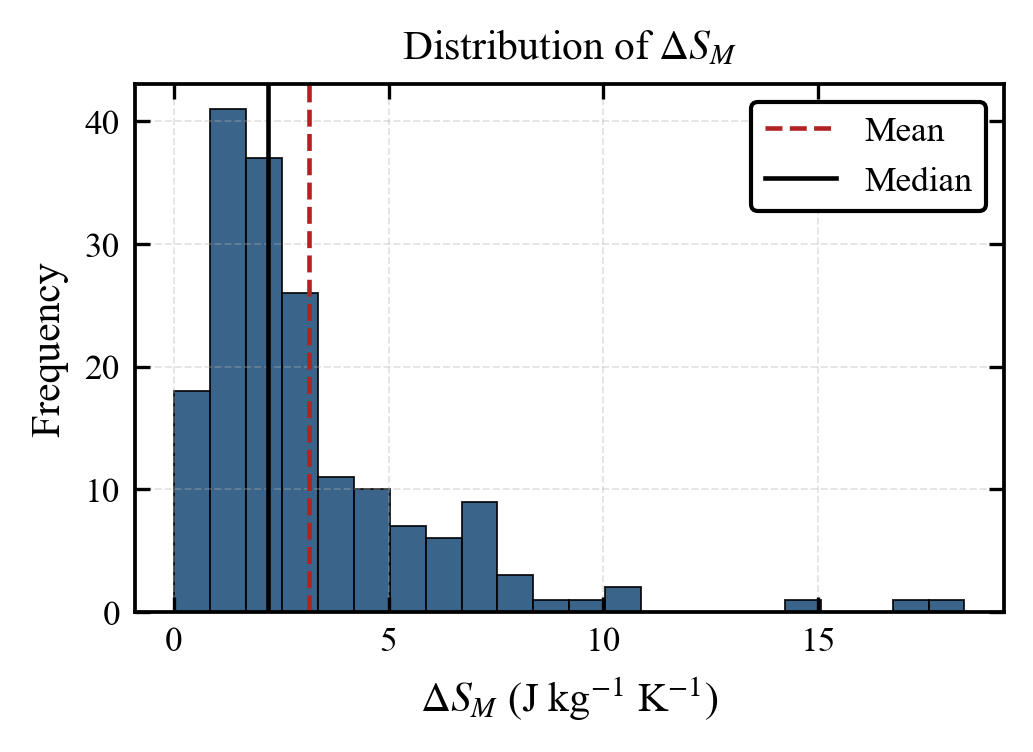

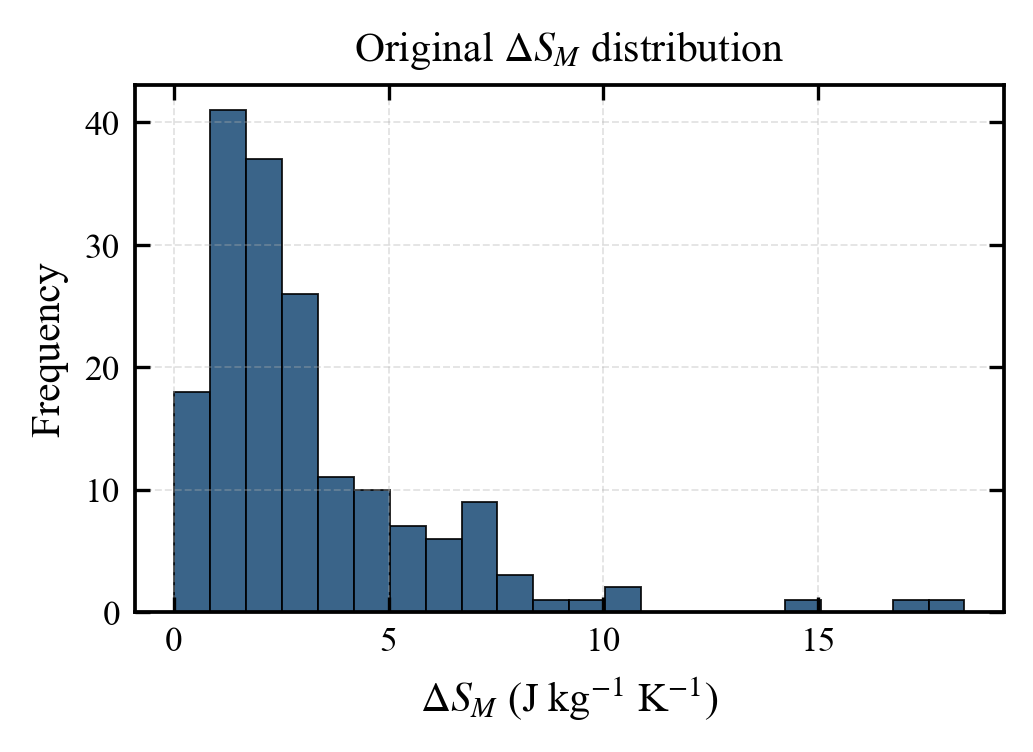

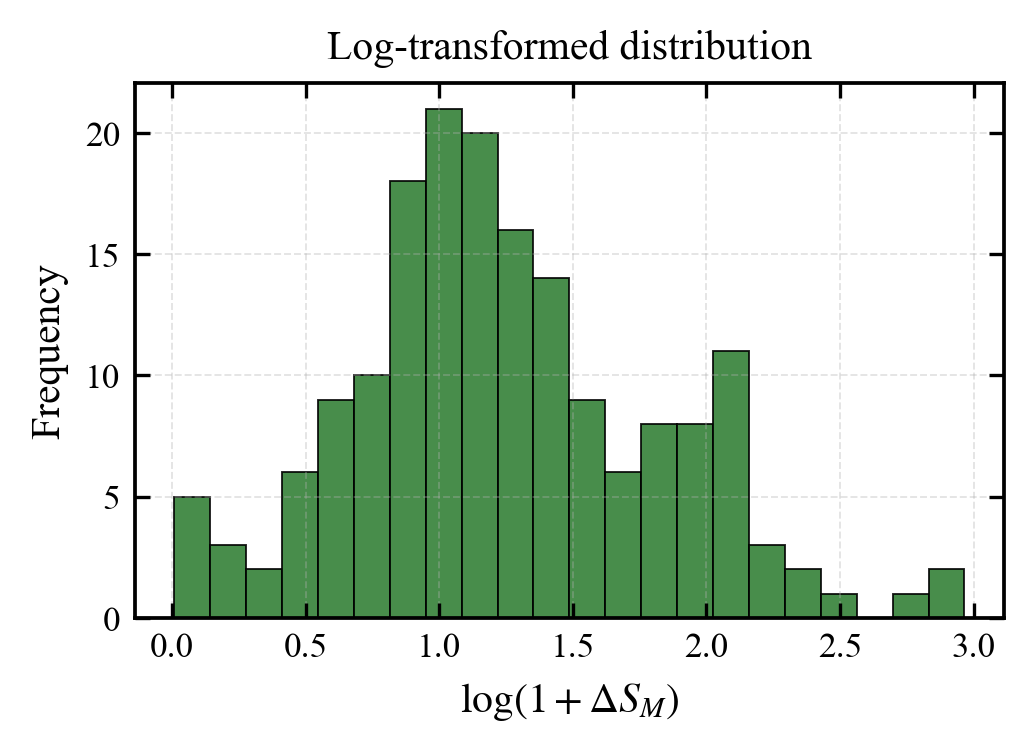

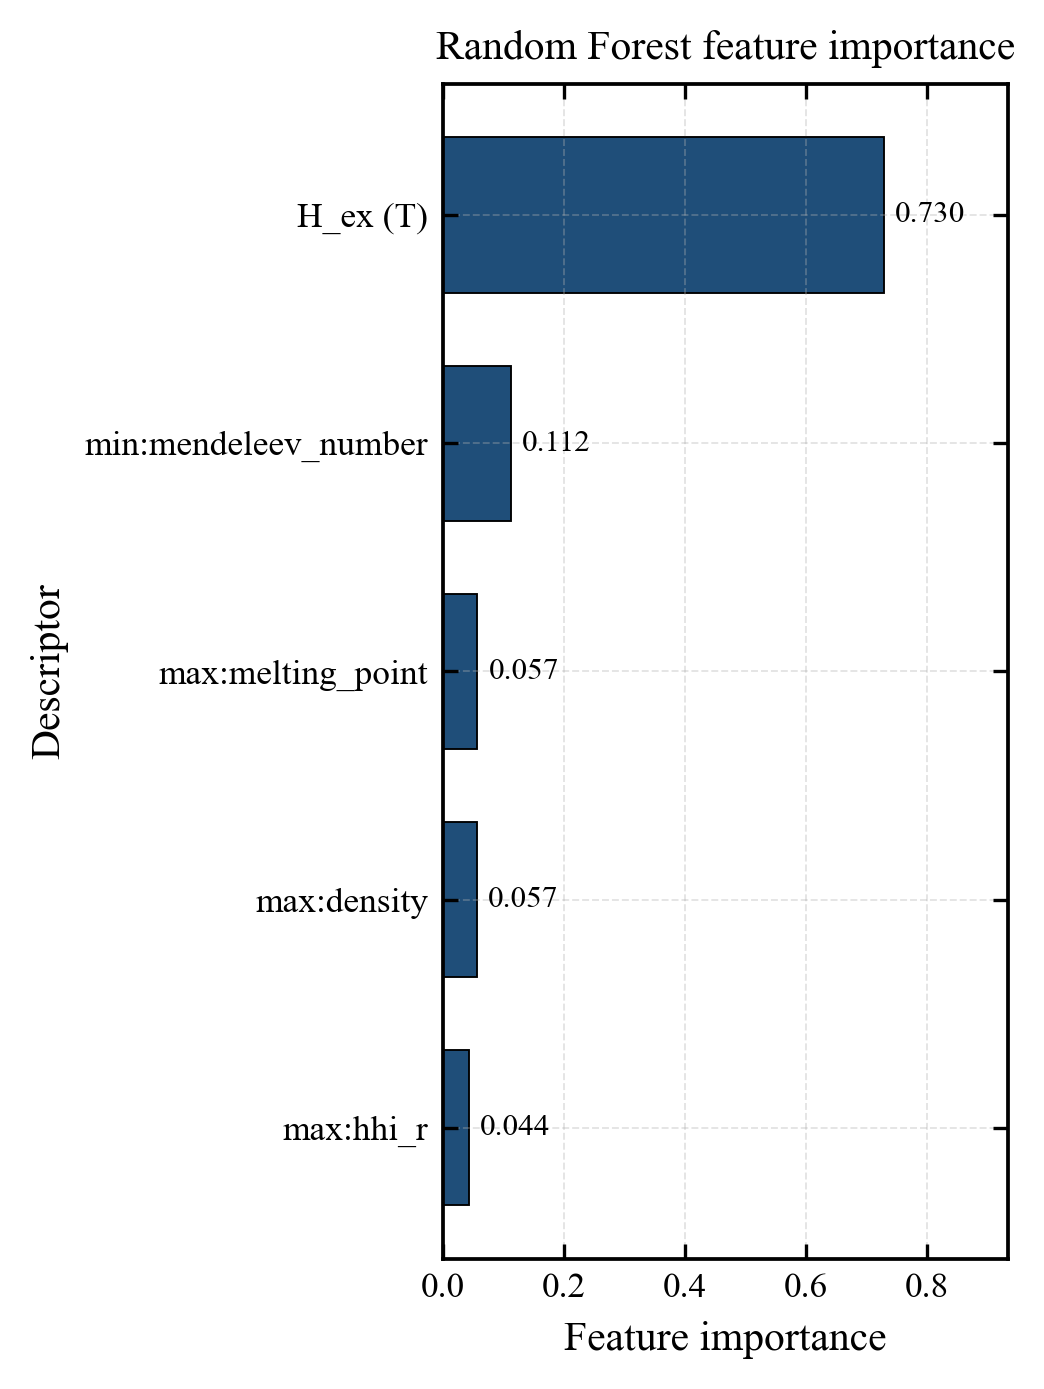

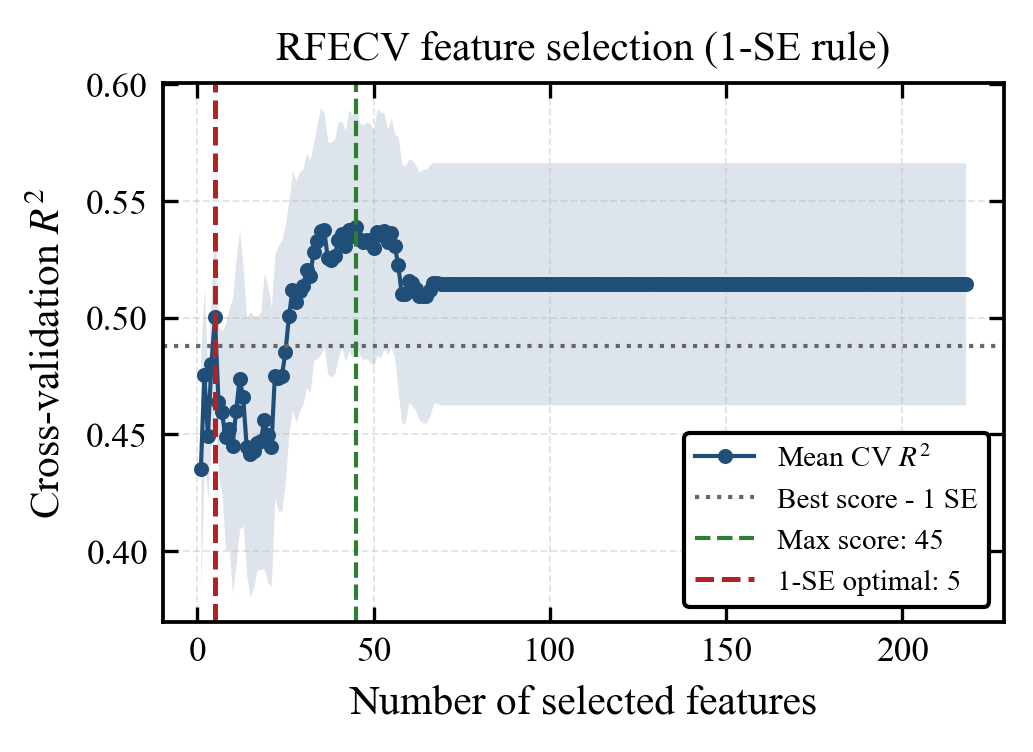

Best mean CV R^2 = 0.5387 at 45 features
1-SE rule selects 5 features (threshold = 0.4879)


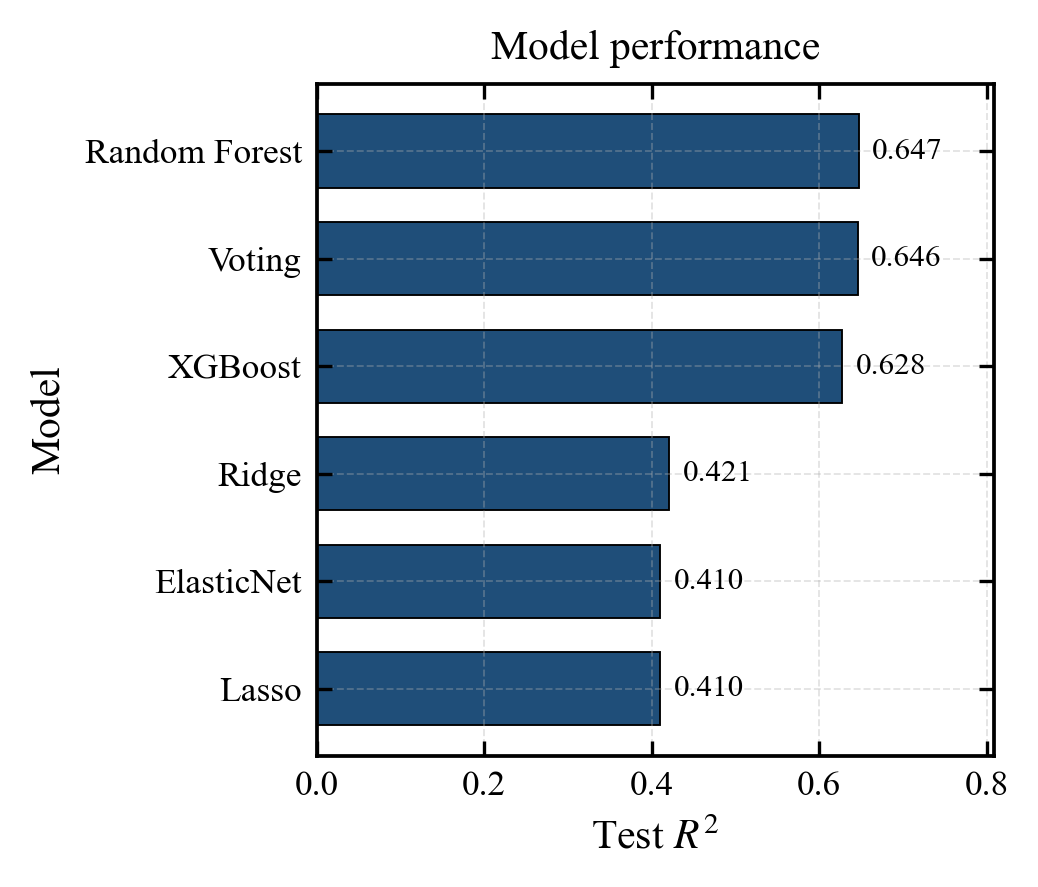

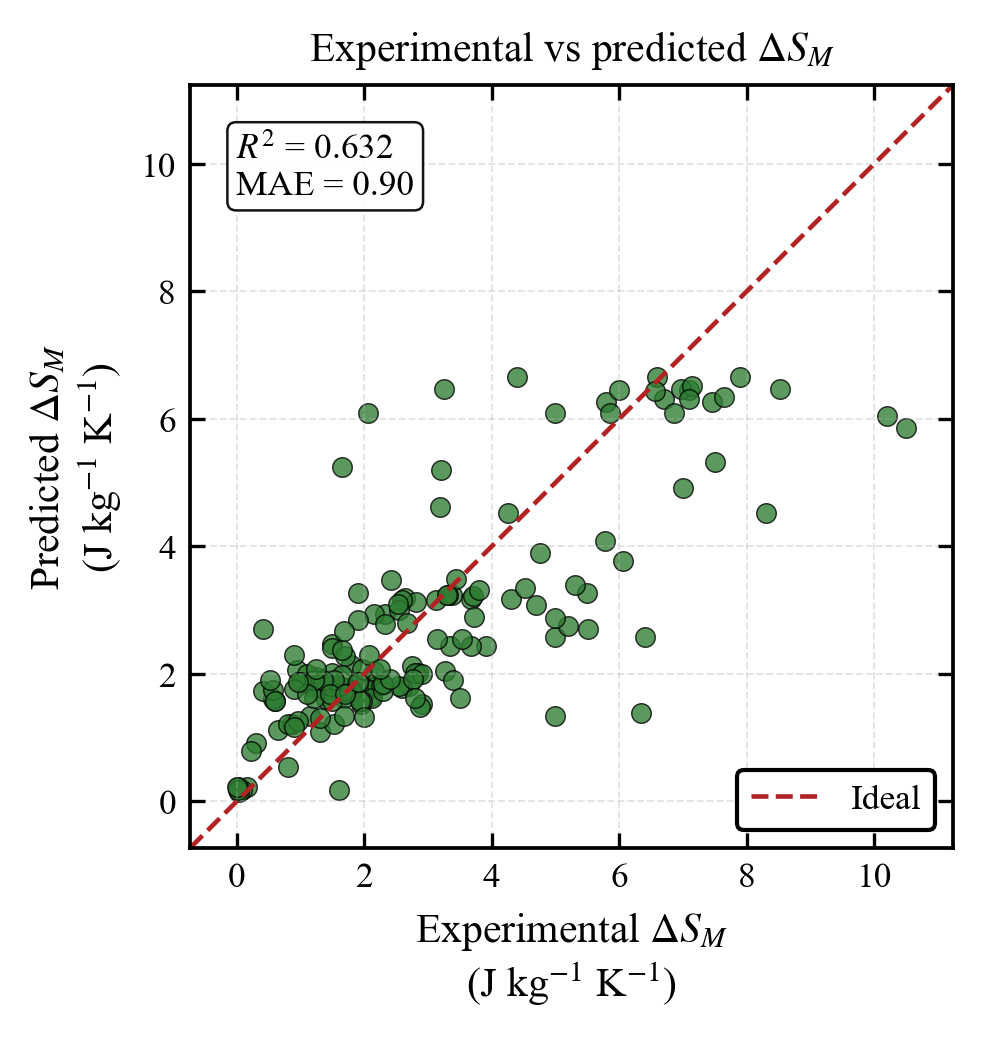

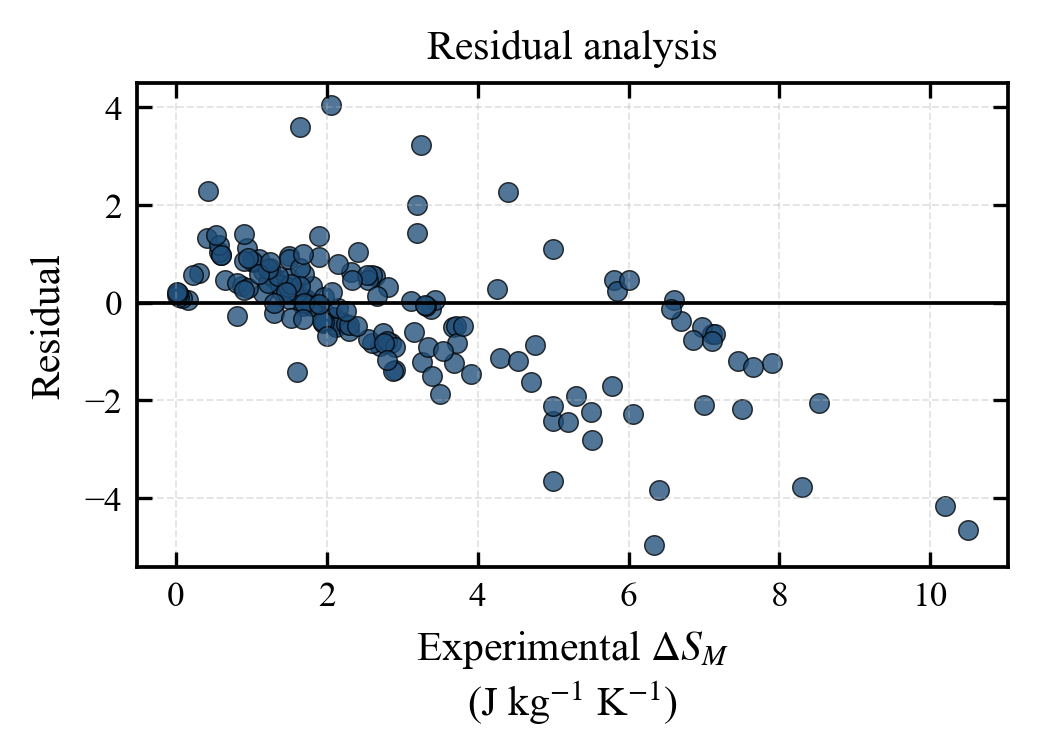

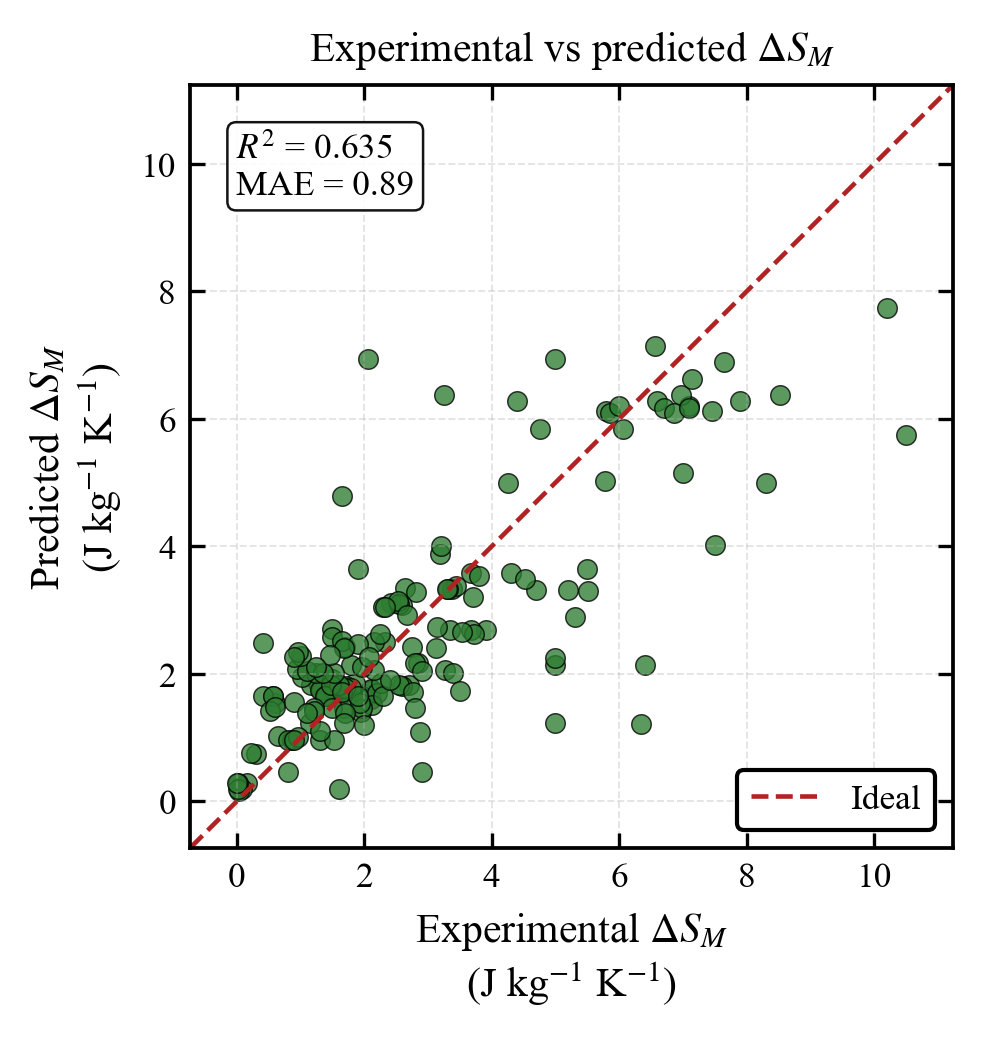

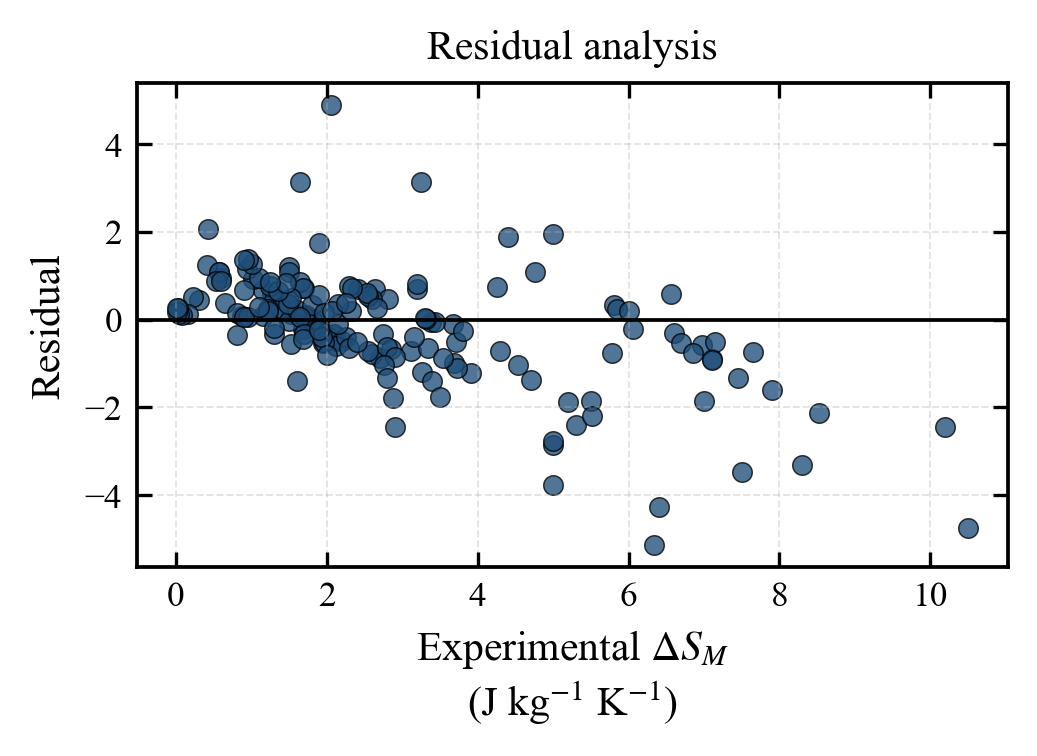

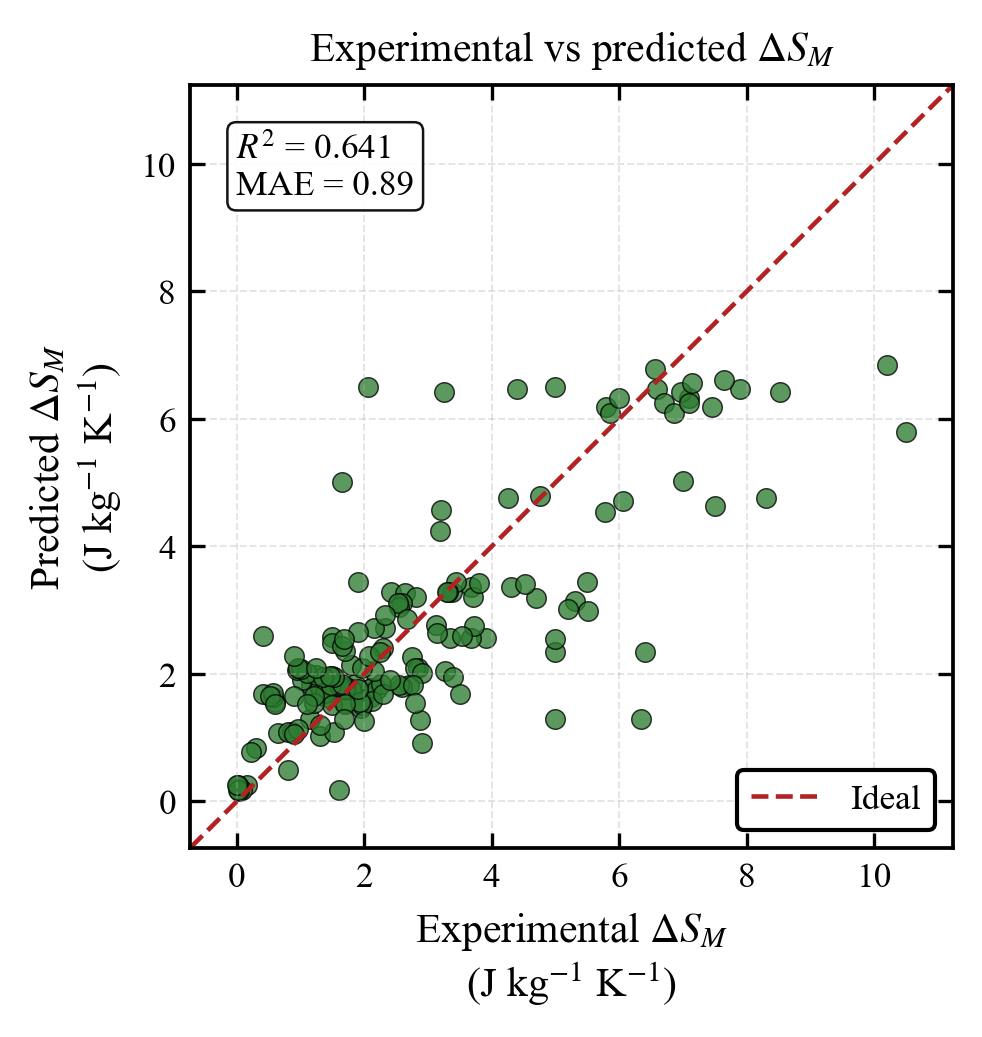

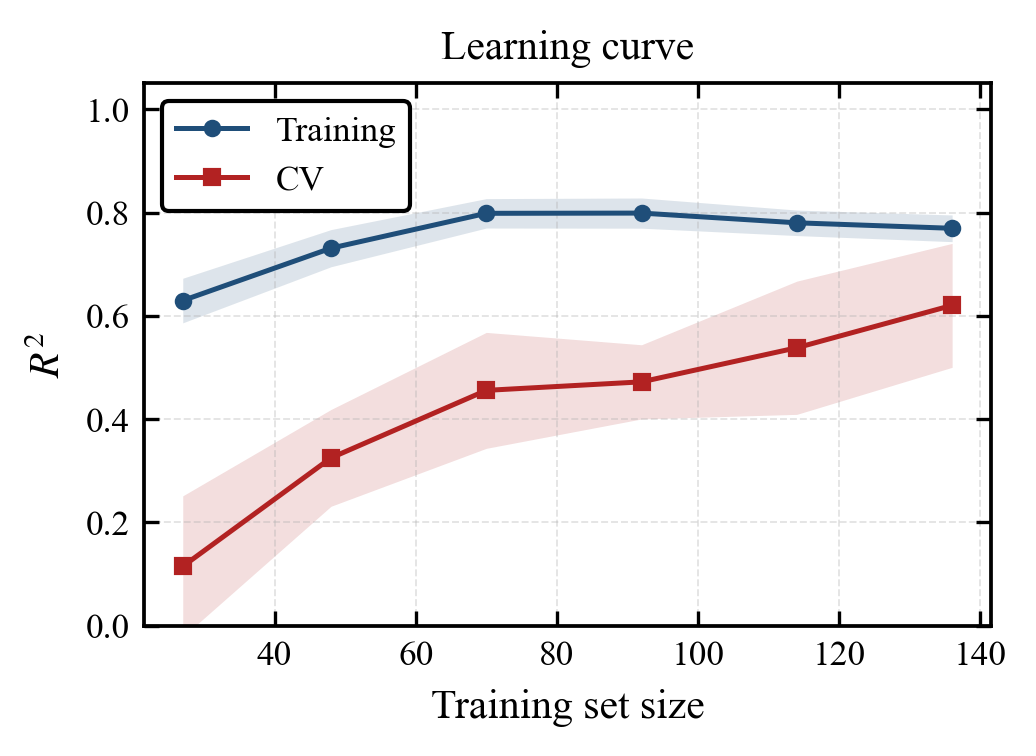

In [23]:
plot_delta_s_histogram(delta_s)
plot_transformation_histogram(y_orig)

rf_importances = best_rf_clean.feature_importances_

# 2. Собираем аккуратный DataFrame
rf_imp_df = pd.DataFrame({
    "feature": selected_features,
    "rf_importance": rf_importances
}).sort_values("rf_importance", ascending=False)

# 3. Строим график
plot_feature_importance(rf_imp_df, top_n=12)

# RFECV
_min_feat = 1
one_se_stats = plot_rfecv_curve_one_se(rfecv, min_features_to_select=_min_feat)

# Сравнение моделей на чистых данных
plot_model_comparison(results_clean_df)

# Parity & Residual plots (на очищенной выборке)
plot_parity(y_clean_orig, predictions_clean_orig["Random Forest"], name="random_forest")
plot_residuals(y_clean_orig, predictions_clean_orig["Random Forest"], name="random_forest")

plot_parity(y_clean_orig, predictions_clean_orig["XGBoost"], name="xgboost")
plot_residuals(y_clean_orig, predictions_clean_orig["XGBoost"], name="xgboost")

plot_parity(y_clean_orig, predictions_clean_orig["Voting"], name="voting")

# Кривая обучения
plot_learning_curve(
    train_sizes_abs,
    train_mean,
    test_mean,
    train_std,
    test_std
)

# Сохранение финальных таблиц Excel

In [24]:
# Сохранение финальных таблиц Excel
results_df.to_excel(os.path.join(out_dir, "model_metrics_transformed.xlsx"), index=False)
results_orig_df.to_excel(os.path.join(out_dir, "model_metrics_original_units.xlsx"), index=False)

# Сохраняем актуальную важность признаков из Random Forest
rf_imp_df.to_excel(os.path.join(out_dir, "feature_importance_random_forest.xlsx"), index=False)

print(f"\nAll figures and tables saved to folder: {out_dir}")


All figures and tables saved to folder: DCD_paper
